# Setup and Data Loading

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# This is simply for aesthetic purposes
sns.set_theme(style="whitegrid")
plt.rcParams.update({'figure.autolayout': True})

outputs = "../Results/Descriptive_stats/"


# Loading of the clean and balaneced panel data prepared in data_prearation.ipynb

descriptive_df_panel = pd.read_csv("../Data/prepared_panel_data.csv")

# Those are our outcomes variables, where most of the descriptive analysis will be focused on
numeric_vars = ["log_CO2_per_nm", "Avg Speed (kn)", "Distance (nm)", "MGO_Share", "HSFO_Share", "VLSFO_Share"]

In [ ]:
# Means of the variables that were used to build the clusters, by trade profile.

cluster_features = ["ETS_Rate", "Distance (nm)", "Avg Speed (kn)", "log_CO2_per_nm", "Vessel Dwt", "MGO_Share"] 

# Most to least exposed, with the residual group last, to have a clean ordering in the visualizations and tables.
cluster_order = ["High EU", "Med EU", "Low EU", "Other"]

# Mean of each clustering feature, by cluster
cluster_profile = (
    descriptive_df_panel.groupby("Cluster_Name")[cluster_features]
    .mean()
    .reindex(cluster_order)
    .round(3))

cluster_profile.T.to_csv(f"{outputs}Cluster_Feature_Means.csv")

# Sizes for context (unique ships overlap across clusters, so they sum to >15,781)
cluster_size = descriptive_df_panel.groupby("Cluster_Name").agg(
    Unique_Vessels=("Vessel Name", "nunique"),
    Observations=("Vessel Name", "count")).reindex(cluster_order)

# Display: variables as rows (like the report's Table 3), gradient across clusters
display(cluster_profile.T.style.background_gradient(axis=1, cmap="YlGnBu"))
display(cluster_size)

Cluster_Name,High EU,Med EU,Low EU,Other
ETS_Rate,0.476000,0.043000,0.024000,0.083000
Distance (nm),2805.068000,5697.247000,4273.579000,3728.182000
Avg Speed (kn),10.179000,11.315000,11.325000,10.387000
log_CO2_per_nm,-1.860000,-1.234000,-1.516000,-1.951000
Vessel Dwt,21062.508000,90206.510000,58222.742000,14194.980000
MGO_Share,0.047000,0.023000,0.029000,0.050000


,Unique_Vessels,Observations
Cluster_Name,,
High EU,13664,533273
Med EU,11465,383878
Low EU,15056,829533
Other,2426,9105


# Global summary tables

In [18]:
# Overall summary statistics
global_summary = descriptive_df_panel[numeric_vars].describe().T

# Add a cleaner median column since describe() calls it 50%
global_summary.rename(columns={'50%': 'median'}, inplace=True)

# Save the table to a CSV file
global_summary.to_csv(f"{outputs}Global_Summary_Statistics.csv")

# Pre 2024 vs post 2024 global comparison
pre_post_summary = descriptive_df_panel.groupby("Post2024")[numeric_vars].mean().T
pre_post_summary.columns = ["Pre_2024_Mean", "Post_2024_Mean"]

# Calculate the raw percentage change before econometric controls
pre_post_summary["Raw_Change_%"] = ((pre_post_summary["Post_2024_Mean"] - pre_post_summary["Pre_2024_Mean"]) 
    / pre_post_summary["Pre_2024_Mean"]) * 100

pre_post_summary.to_csv(f"{outputs}Global_Pre_vs_Post_Comparison.csv")

display(global_summary)
display(pre_post_summary)

,count,mean,std,min,25%,median,75%,max
log_CO2_per_nm,1755789.0,-1.561033,0.471212,-2.376617,-1.966385,-1.542133,-1.232798,-0.414553
Avg Speed (kn),1755789.0,10.969730,1.707397,6.396667,9.890000,11.150000,12.180000,14.570000
Distance (nm),1755789.0,4135.995158,3794.847760,213.757702,1318.893917,3092.936167,5478.000500,19027.791043
MGO_Share,1755789.0,0.033221,0.046756,0.000263,0.007637,0.015657,0.038113,0.905180
HSFO_Share,1755789.0,0.064033,0.242499,0.000000,0.000000,0.000000,0.000000,0.999224
VLSFO_Share,1755789.0,0.902746,0.242825,0.000000,0.954387,0.980622,0.991719,0.999737


,Pre_2024_Mean,Post_2024_Mean,Raw_Change_%
log_CO2_per_nm,-1.556203,-1.597261,2.638349
Avg Speed (kn),11.029230,10.523382,-4.586437
Distance (nm),4144.810834,4069.863651,-1.808217
MGO_Share,0.033078,0.034299,3.692876
HSFO_Share,0.062271,0.077253,24.059275
VLSFO_Share,0.904652,0.888448,-1.791124


# Cluster breakdown tables

In [ ]:
# Cluster size and demographics
cluster_counts = descriptive_df_panel.groupby("Cluster_Name").agg(Total_Observations=("Vessel Name", "count"),
    Unique_Vessels=("Vessel Name", "nunique"))

cluster_counts.to_csv(f"{outputs}Cluster_Population_Counts.csv")

# 2. Cluster Baseline Behavior (Means by Cluster)

cluster_means = descriptive_df_panel.groupby("Cluster_Name")[numeric_vars].mean().T
cluster_means.to_csv(f"{outputs}Cluster_Variable_Means.csv")

display(cluster_counts)
display(cluster_means.style.background_gradient(axis=1, cmap="YlGnBu"))

,Total_Observations,Unique_Vessels
Cluster_Name,,
High EU,533273,13664
Low EU,829533,15056
Med EU,383878,11465
Other,9105,2426


Cluster_Name,High EU,Low EU,Med EU,Other
log_CO2_per_nm,-1.859647,-1.516039,-1.234178,-1.951360
Avg Speed (kn),10.178556,11.324845,11.315247,10.387141
Distance (nm),2805.067683,4273.579200,5697.247219,3728.182384
MGO_Share,0.047390,0.028874,0.022542,0.049711
HSFO_Share,0.024909,0.061922,0.124190,0.011520
VLSFO_Share,0.927701,0.909204,0.853268,0.938770


# Distribution graphs

C:\Users\paris\AppData\Local\Temp\ipykernel_9684\295563835.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


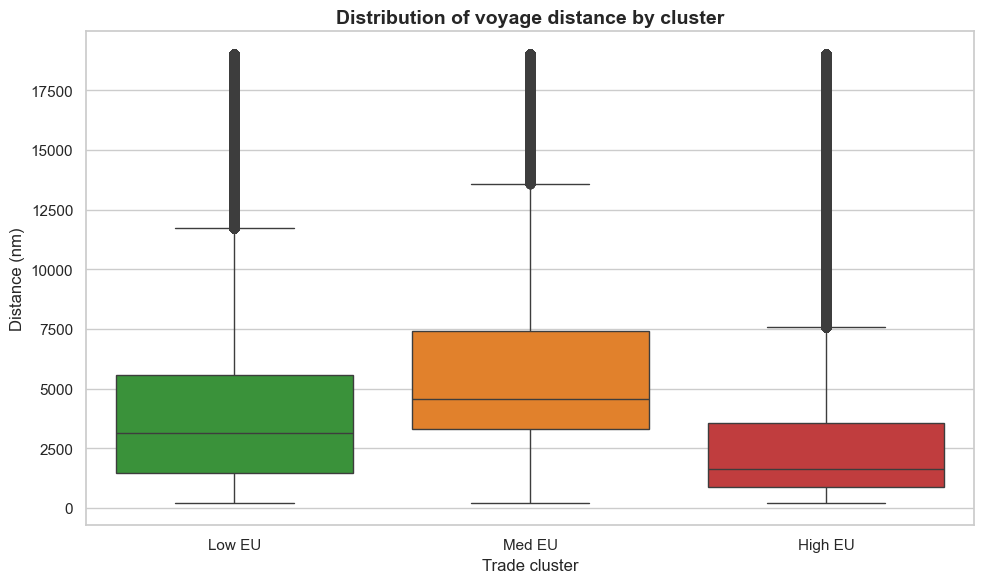

C:\Users\paris\AppData\Local\Temp\ipykernel_9684\295563835.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


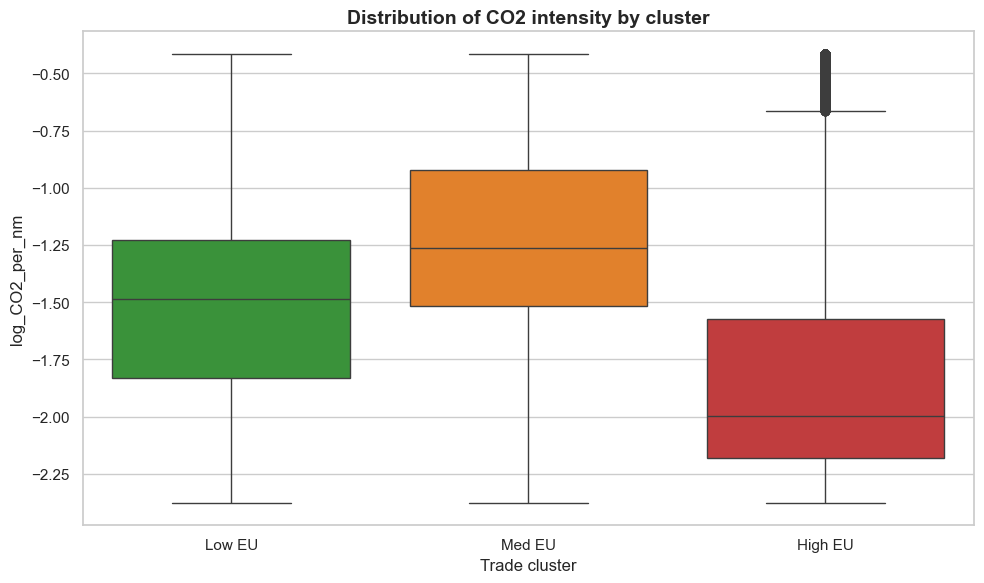

C:\Users\paris\AppData\Local\Temp\ipykernel_9684\295563835.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


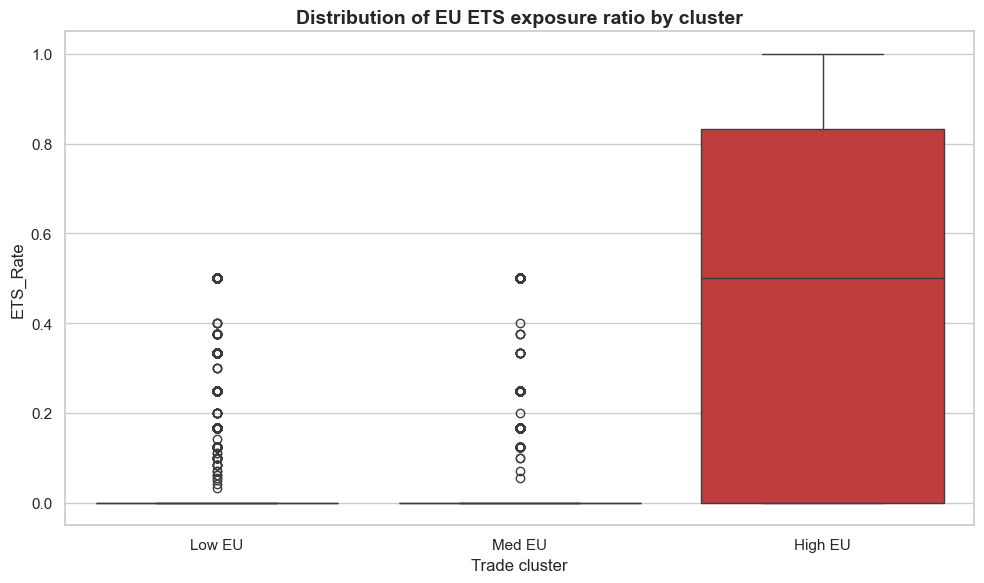

C:\Users\paris\AppData\Local\Temp\ipykernel_9684\295563835.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


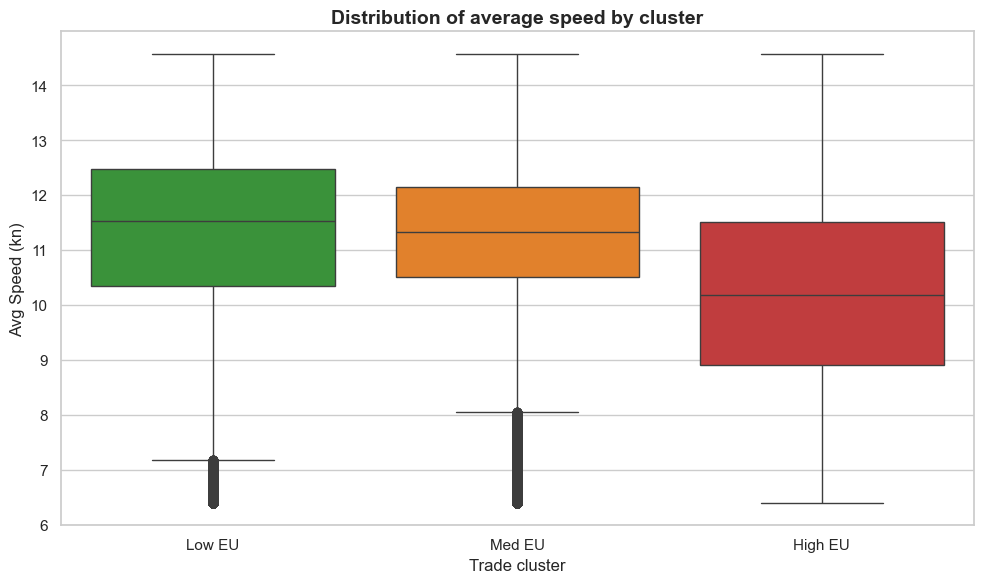

C:\Users\paris\AppData\Local\Temp\ipykernel_9684\295563835.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


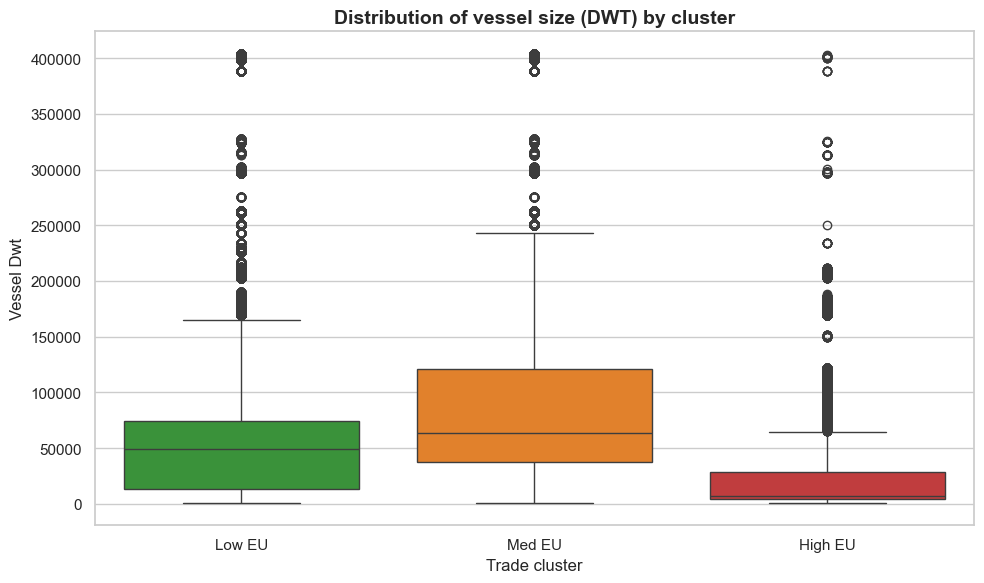

C:\Users\paris\AppData\Local\Temp\ipykernel_9684\295563835.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


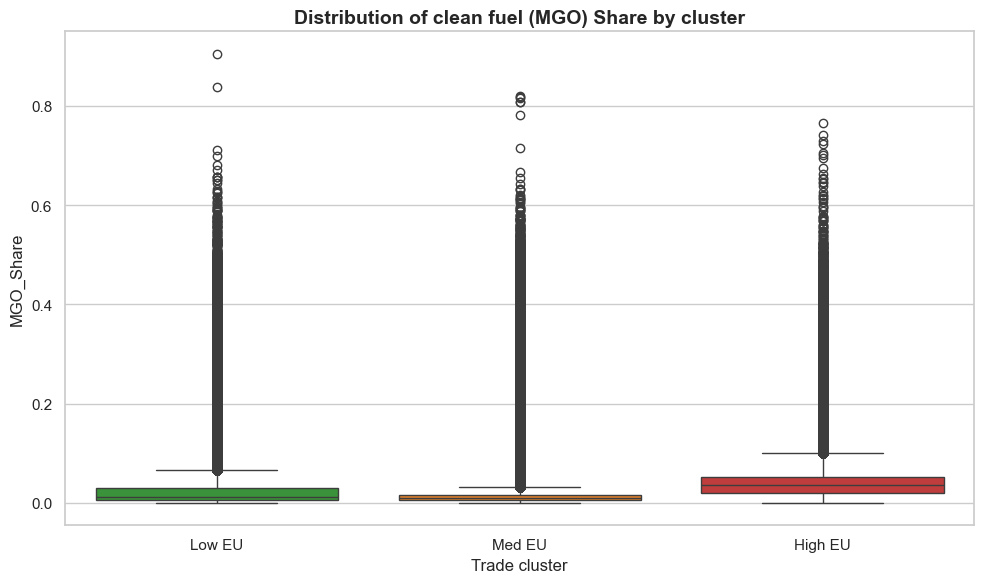

In [20]:
# Define all the variables used to make the clusters (apart from lade, since it is binary)
plots_to_make = {
    "Distance (nm)": "Distribution of voyage distance by cluster",
    "log_CO2_per_nm": "Distribution of CO2 intensity by cluster",
    "ETS_Rate": "Distribution of EU ETS exposure ratio by cluster",
    "Avg Speed (kn)": "Distribution of average speed by cluster",
    "Vessel Dwt": "Distribution of vessel size (DWT) by cluster",
    "MGO_Share": "Distribution of clean fuel (MGO) Share by cluster"}

# We filter out the "Other" cluster so the plots only show our 3 main groups
df_plot = descriptive_df_panel[descriptive_df_panel["Cluster_Name"].isin(["Low EU", "Med EU", "High EU"])]

# Color dictionary to keep it perfectly consistent with your Pre-Trend charts
cluster_colors = {
    "Low EU": "#2ca02c", 
    "Med EU": "#ff7f0e", 
    "High EU": "#d62728"}

# Loop through and create a boxplot for each
for var, title in plots_to_make.items():
    plt.figure(figsize=(10, 6))
    
    # Create the boxplot
    sns.boxplot(
        data=df_plot, 
        x="Cluster_Name", 
        y=var, 
        palette=cluster_colors,
        order=["Low EU", "Med EU", "High EU"])
    
    # Formatting
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel("Trade cluster", fontsize=12)
    plt.ylabel(var, fontsize=12)
    
    # Clean variable name for saving the file safely
    safe_name = var.replace(" ", "_").replace("(", "").replace(")", "").replace("/", "_")
    plt.savefig(f"{outputs}Boxplot_{safe_name}.png", dpi=300)
    
    plt.tight_layout()
    plt.show()    
    plt.close()

# Time series graphs (quarterly, spanning from 2013 to 2025)

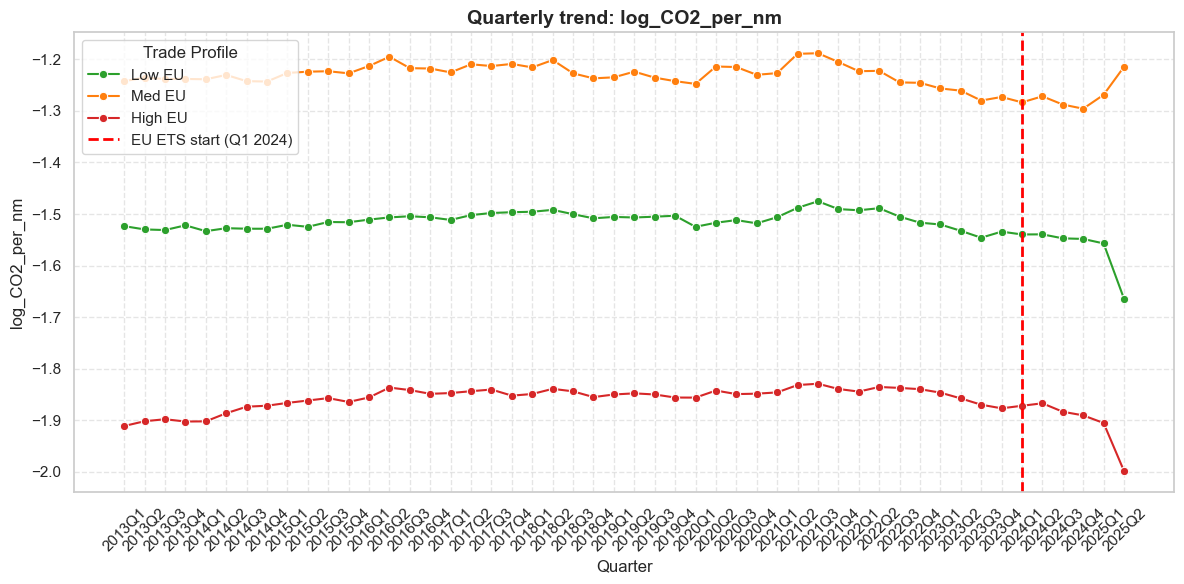

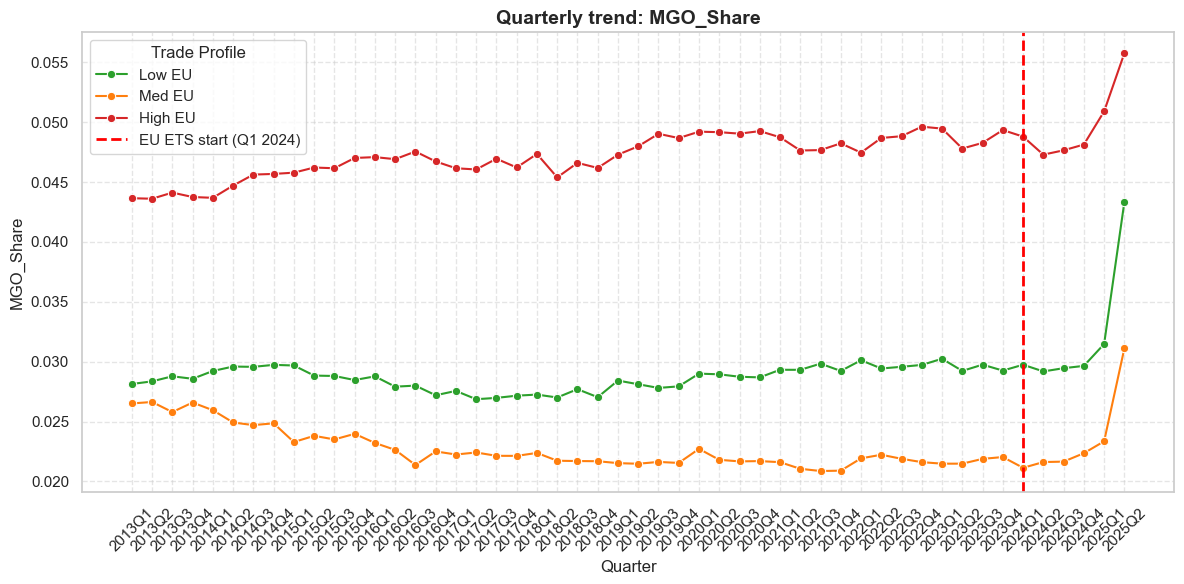

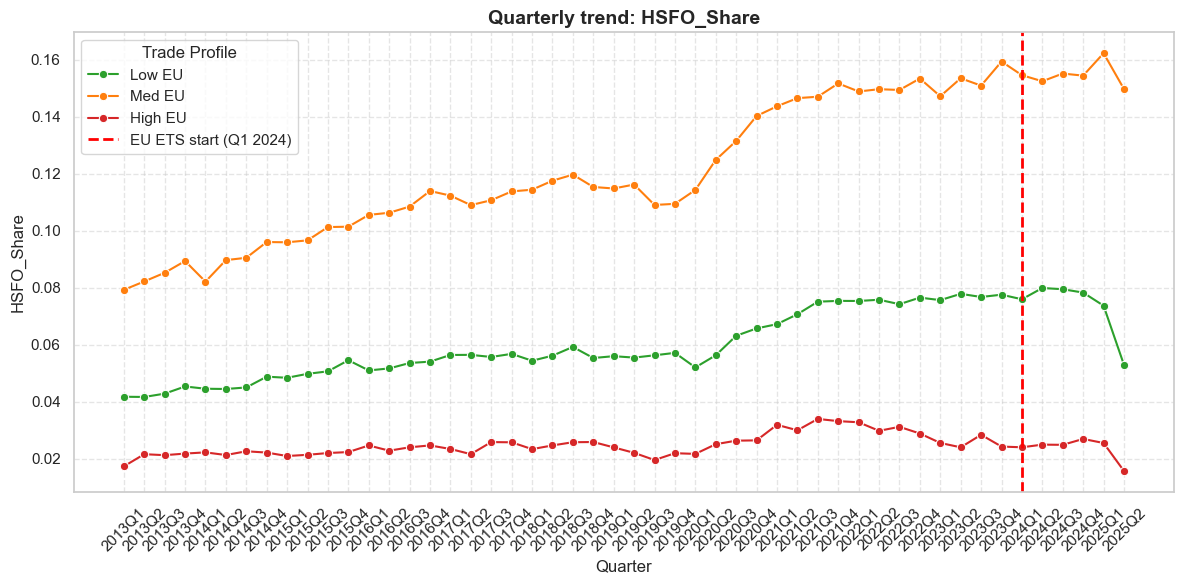

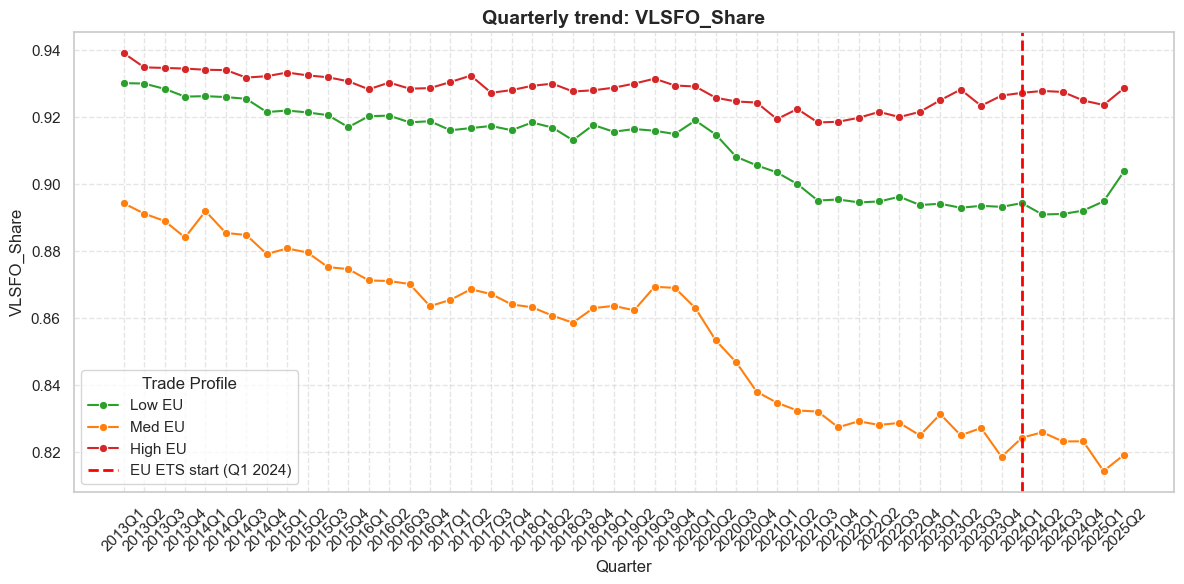

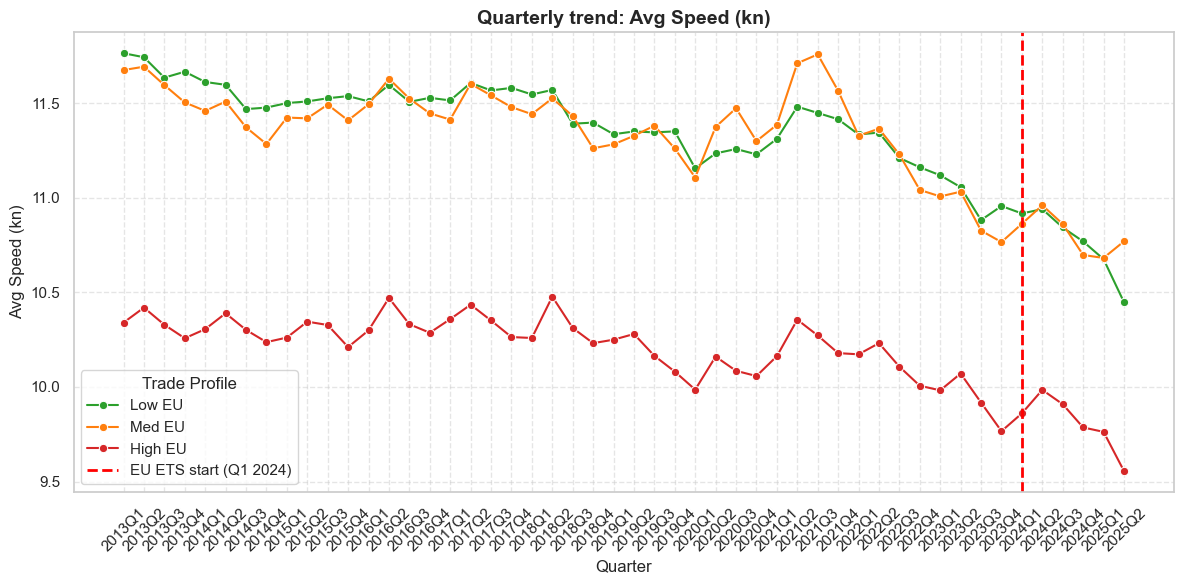

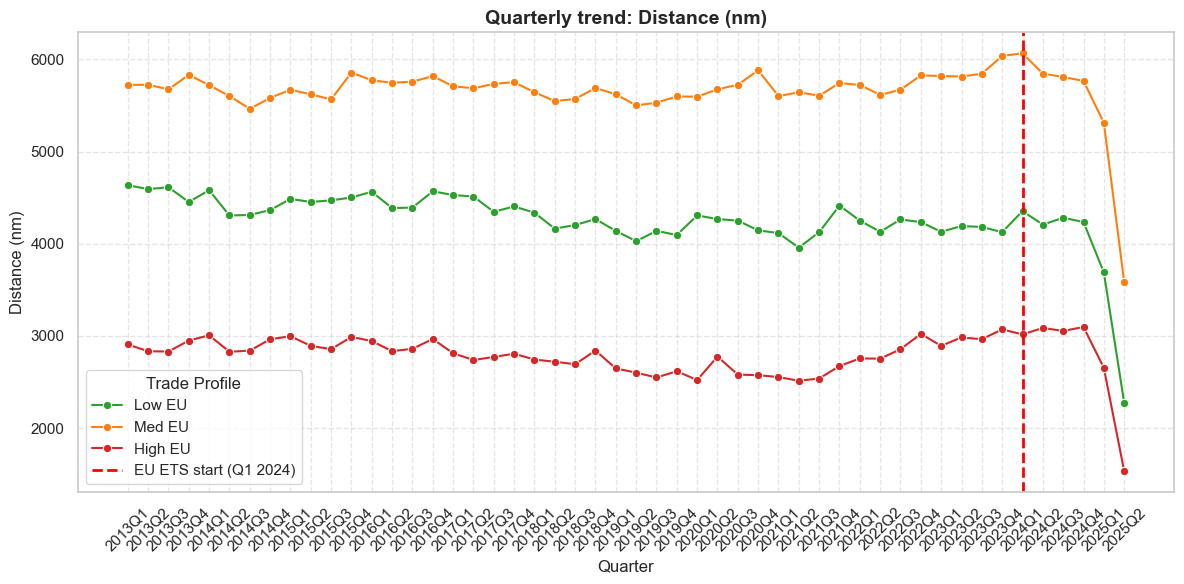

In [21]:
outcomes = [
    "log_CO2_per_nm", 
    "MGO_Share", 
    "HSFO_Share", 
    "VLSFO_Share", 
    "Avg Speed (kn)", 
    "Distance (nm)"]

descriptive_df_panel['Date'] = pd.to_datetime(descriptive_df_panel['YearMonth'])
descriptive_df_panel['YearQuarter'] = descriptive_df_panel['Date'].dt.to_period('Q').astype(str)

# Group by quarter and cluster, then calculate the mean for all outcomes
quarterly_df = descriptive_df_panel.groupby(['YearQuarter', 'Cluster_Name'])[outcomes].mean().reset_index()

# Ensure chronological sorting
quarterly_df = quarterly_df.sort_values("YearQuarter")

# Filter out the "Other" cluster to keep the plots clean
quarterly_df = quarterly_df[quarterly_df["Cluster_Name"].isin(["Low EU", "Med EU", "High EU"])]

# Color dictionary to keep it perfectly consistent with your other visualisations
cluster_colors = {
    "Low EU": "#2ca02c", 
    "Med EU": "#ff7f0e", 
    "High EU": "#d62728"}

# Looping and plotting
for var in outcomes:
    plt.figure(figsize=(12, 6)) 
    
    # Plot a line for each cluster over time
    sns.lineplot(
        data=quarterly_df, 
        x="YearQuarter", 
        y=var, 
        hue="Cluster_Name",
        marker="o",
        errorbar=None,
        palette=cluster_colors,
        hue_order=["Low EU", "Med EU", "High EU"]) 
    
    # Find the index of Q1 2024 to place the vertical dashed red line
    unique_quarters = list(quarterly_df["YearQuarter"].unique()) 
    policy_idx = unique_quarters.index("2024Q1") 
    plt.axvline(x=policy_idx, color='red', linestyle='--', linewidth=2, label='EU ETS start (Q1 2024)') 
    
    # Formatting
    plt.title(f"Quarterly trend: {var}", fontsize=14, fontweight='bold') 
    plt.xlabel("Quarter", fontsize=12) 
    plt.ylabel(var, fontsize=12) 
    plt.xticks(rotation=45) 
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(title="Trade Profile") 
    plt.tight_layout()
    
    # Save
    safe_name = var.replace(" ", "_").replace("(", "").replace(")", "").replace("/", "_") 
    plt.savefig(f"{outputs}TimeSeries_Quarterly_{safe_name}.png", dpi=300) 
    
    plt.show() 
    plt.close()

# Time series graphs (monthly, for the year before the shock)

2023 Pre-policy sample size: 160692 voyages


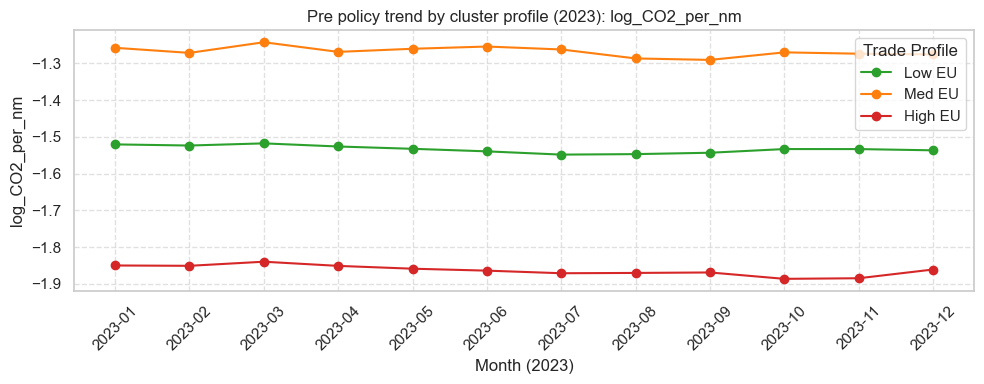

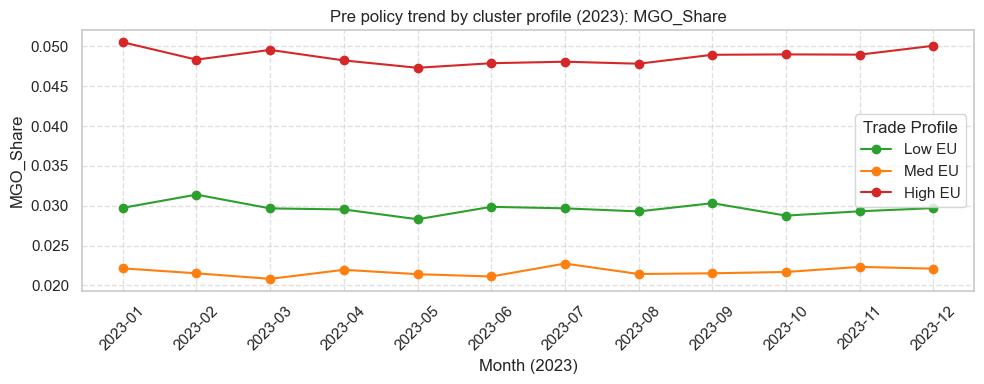

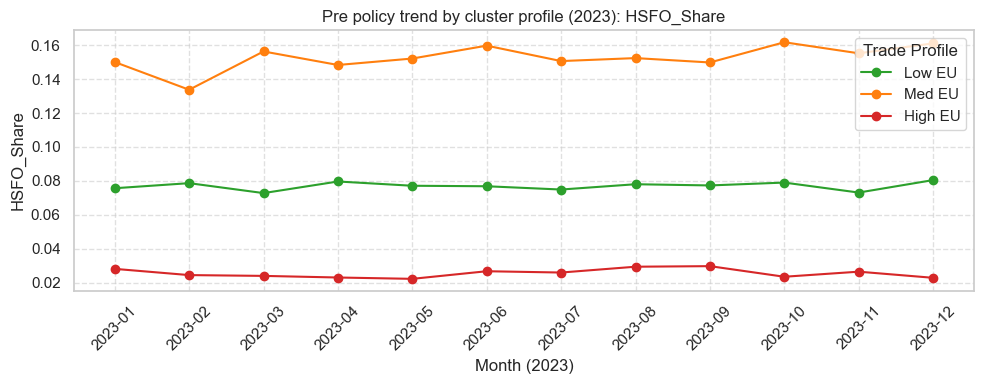

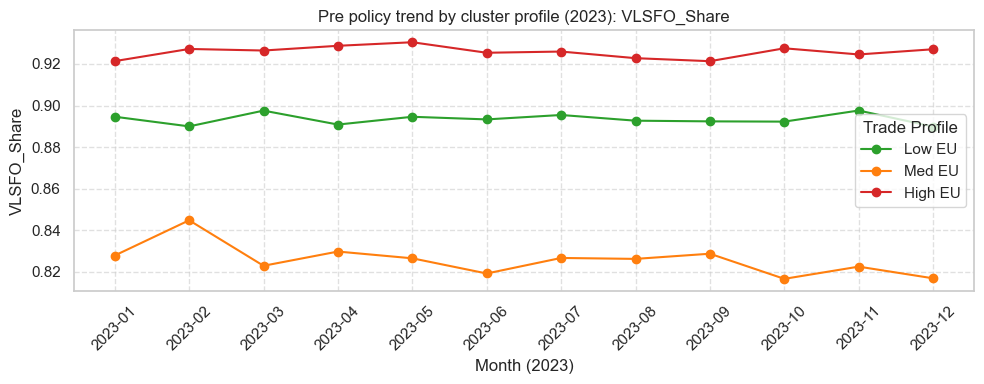

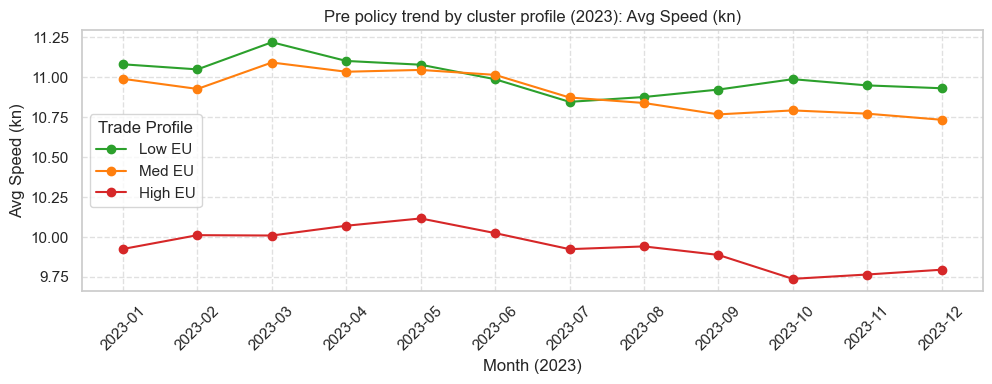

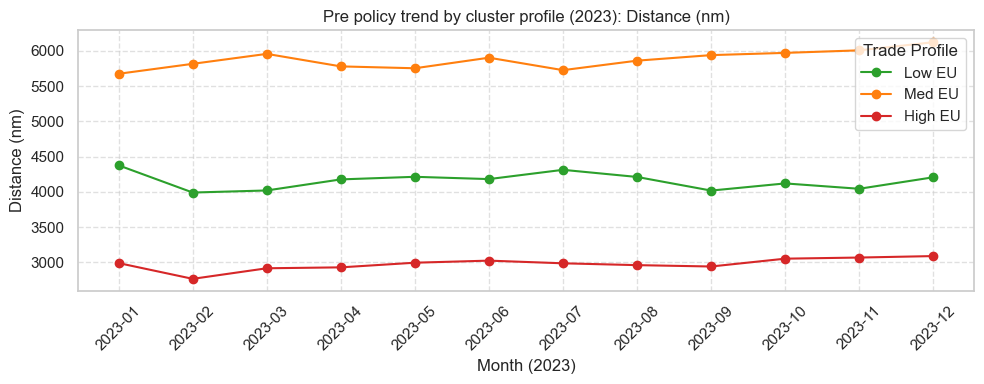

In [22]:
outcomes = [
    "log_CO2_per_nm", 
    "MGO_Share", 
    "HSFO_Share", 
    "VLSFO_Share", 
    "Avg Speed (kn)", 
    "Distance (nm)"]


# Filter strictly to the 12 months before the policy (2023)
mask_2023 = descriptive_df_panel['YearMonth'].str.startswith('2023')
df_2023 = descriptive_df_panel[mask_2023].copy()

print(f"2023 Pre-policy sample size: {len(df_2023)} voyages")

# =======================================================
# We filter out the "Other" group to focus purely on the 3 main clusters
clusters_to_plot = ["Low EU", "Med EU", "High EU"]
df_clusters_2023 = df_2023[df_2023['Cluster_Name'].isin(clusters_to_plot)]

# Calculate means grouped by month and cluster
cluster_summary = df_clusters_2023.groupby(['YearMonth', 'Cluster_Name'])[outcomes].mean().reset_index()
cluster_summary.to_csv(os.path.join(outputs, 'Pretrend_Cluster_MonthlyMeans_2023.csv'), index=False)

# Color coding for consistency with your other visualisations
cluster_colors = {"Low EU": "#2ca02c", "Med EU": "#ff7f0e", "High EU": "#d62728"}

for outcome in outcomes:
    plt.figure(figsize=(10, 4))
    
    # Plot a separate line for each cluster
    for cluster in clusters_to_plot:
        subset = cluster_summary[cluster_summary['Cluster_Name'] == cluster]
        plt.plot(subset['YearMonth'], subset[outcome], marker='o', 
                 color=cluster_colors.get(cluster, 'blue'), label=cluster)
    
    plt.xticks(rotation=45)
    plt.xlabel('Month (2023)')
    plt.ylabel(outcome)
    plt.title(f'Pre policy trend by cluster profile (2023): {outcome}')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(title="Trade Profile")
    plt.tight_layout()
    
    # Save
    safe_outcome = outcome.replace(' ', '_').replace('(', '').replace(')', '')
    plt.savefig(os.path.join(outputs, f'Pretrend_Cluster_{safe_outcome}.png'), dpi=300)
    plt.show()
    plt.close()